# Risk Prediction Overview

## Phase 0: Directory location

In [1]:
import sys
from pathlib import Path

# Add the project root to Python path
project_root = Path.cwd().parent  # Goes up one level from notebooks/
sys.path.insert(0, str(project_root))

## Phase 1: Modules linked

In [2]:
# 1. Enable Auto-reloading
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# 2. Import your heavy logic from your Python file
from core.gnn_layer.risk_predict import (
    fetch_graph_from_neo4j, 
    RiskEscalationGNN, 
    train_model, 
    evaluate_model
)

from core.kg_sna_layer.graph_builder import(
    AsyncKnowledgeGraphManager,
    wipe_sna_metrics
)

print("Environment linked and modules loaded successfully!")

c:\Users\dhara\anaconda3\envs\sna_oms_thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment linked and modules loaded successfully!


In [3]:
import torch
import random
import numpy as np

# Lock the random seed for 100% reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

## Phase 2: Fetching data

In [4]:
from core.config import graph_base
print("Fetching graph data from Neo4j...")
kg_manager = AsyncKnowledgeGraphManager(graph_base.URL, graph_base.USER, graph_base.PASS)

Fetching graph data from Neo4j...


In [5]:
#Running wipe_sna_metrics() 
wipe_sna_metrics(graph_base.URL, graph_base.USER, graph_base.PASS)
baseline_data, enriched_data, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data.num_nodes} nodes and {baseline_data.num_edges} edges before SNA calculations.")
print(f"Total High-Risk Edges (Class 1): {int(enriched_data.y.sum().item())}")

✅ Deleted SNA_TIE_STRENGTH edges.
✅ Removed structural metrics (betweenness, eigenvector, etc.) from nodes.
🧹 Graph successfully reset to its pure semantic state!
Successfully loaded 47 nodes and 124 edges before SNA calculations.
Total High-Risk Edges (Class 1): 3


In [6]:
#Running calculate_sna_metrics()
await kg_manager.calculate_sna_metrics()
baseline_data_sna, enriched_data_sna, reverse_mapping_sna = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data_sna.num_nodes} nodes and {baseline_data_sna.num_edges} edges with SNA calculations.")
print(f"Total High-Risk Edges (Class 1): {int(enriched_data_sna.y.sum().item())}")

✅ Structural Metrics (Betweenness, Eigenvector, Closeness) updated.
Successfully loaded 47 nodes and 124 edges with SNA calculations.
Total High-Risk Edges (Class 1): 3


## Phase 3: Initialize and train models

In [7]:
# Initialize
baseline_model = RiskEscalationGNN(num_node_features=1, hidden_channels=16)
enriched_model = RiskEscalationGNN(num_node_features=3, hidden_channels=16)

# Train
print("--- Training Baseline Model ---")
trained_baseline = train_model(baseline_model, baseline_data, epochs=100)
print("--- Training Baseline Model with SNA ---")
trained_baseline_sna = train_model(baseline_model, baseline_data_sna, epochs=100)

print("\n--- Training Enriched Model ---")
trained_enriched = train_model(enriched_model, enriched_data, epochs=100)
print("--- Training Enriched Model with SNA ---")
trained_enriched_sna = train_model(enriched_model, enriched_data_sna, epochs=100)

--- Training Baseline Model ---
Epoch 000 | Loss: 1.4050
Epoch 020 | Loss: 1.3013
Epoch 040 | Loss: 1.3650
Epoch 060 | Loss: 1.3883
Epoch 080 | Loss: 1.3796
--- Training Baseline Model with SNA ---
Epoch 000 | Loss: 1.3906
Epoch 020 | Loss: 1.3654
Epoch 040 | Loss: 1.4199
Epoch 060 | Loss: 1.3190
Epoch 080 | Loss: 1.4322

--- Training Enriched Model ---
Epoch 000 | Loss: 1.3535
Epoch 020 | Loss: 1.3528
Epoch 040 | Loss: 1.3528
Epoch 060 | Loss: 1.3528
Epoch 080 | Loss: 1.3528
--- Training Enriched Model with SNA ---
Epoch 000 | Loss: 1.3528
Epoch 020 | Loss: 1.3563
Epoch 040 | Loss: 1.2990
Epoch 060 | Loss: 1.2111
Epoch 080 | Loss: 0.9329


## Phase 4: AUC

FINAL ABLATION STUDY RESULTS:
WITHOUT SNA:
Baseline GNN -> AUC: 0.500 | Recall: 1.000
Enriched KG  -> AUC: 0.550 | Recall: 1.000
WITH SNA:
Baseline GNN -> AUC: 0.500 | Recall: 1.000
Enriched KG  -> AUC: 0.901 | Recall: 1.000


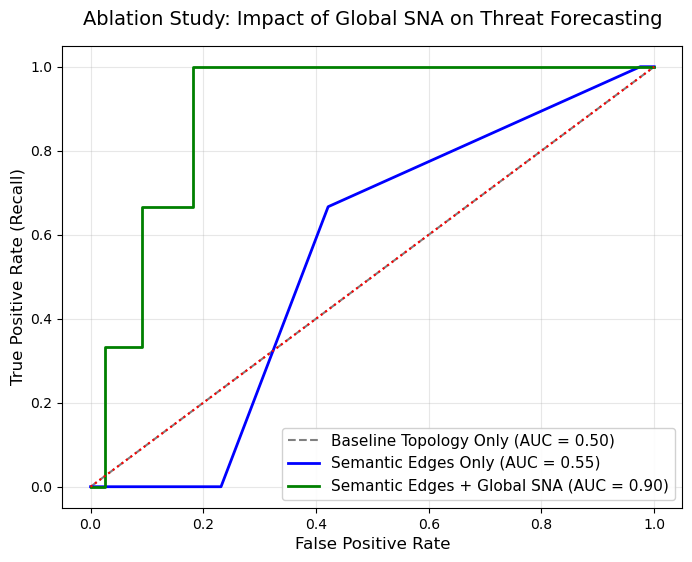

In [8]:
from datetime import datetime
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
# Evaluate
base_auc, base_recall, y_true_b, preds_b = evaluate_model(trained_baseline, baseline_data)
enr_auc, enr_recall, y_true_e, preds_e = evaluate_model(trained_enriched, enriched_data)

# Evaluate with SNA
base_auc_sna, base_recall_sna, y_true_b_sna, preds_b_sna = evaluate_model(trained_baseline_sna, baseline_data_sna)
enr_auc_sna, enr_recall_sna, y_true_e_sna, preds_e_sna = evaluate_model(trained_enriched_sna, enriched_data_sna)


print("="*30)
print("FINAL ABLATION STUDY RESULTS:")
print("="*30)
print("WITHOUT SNA:")
print(f"Baseline GNN -> AUC: {base_auc:.3f} | Recall: {base_recall:.3f}")
print(f"Enriched KG  -> AUC: {enr_auc:.3f} | Recall: {enr_recall:.3f}")
print("WITH SNA:")
print(f"Baseline GNN -> AUC: {base_auc_sna:.3f} | Recall: {base_recall_sna:.3f}")
print(f"Enriched KG  -> AUC: {enr_auc_sna:.3f} | Recall: {enr_recall_sna:.3f}")

# Plotting the ROC Curve
fpr_b, tpr_b, _ = roc_curve(y_true_b, preds_b)
fpr_e, tpr_e, _ = roc_curve(y_true_e, preds_e)

#fpr_b_sna, tpr_b_sna, _ = roc_curve(y_true_b_sna, preds_b_sna)
fpr_e_sna, tpr_e_sna, _ = roc_curve(y_true_e_sna, preds_e_sna)

plt.figure(figsize=(8, 6))
plt.plot(fpr_b, tpr_b, linestyle='--', color='gray', label=f'Baseline Topology Only (AUC = {base_auc:.2f})')
plt.plot(fpr_e, tpr_e, color='blue', linewidth=2, label=f'Semantic Edges Only (AUC = {enr_auc:.2f})')
#plt.plot(fpr_b_sna, tpr_b_sna, linestyle='--', color='cyan', label=f'Baseline Binary GNN with SNA (AUC = {base_auc_sna:.2f})')
plt.plot(fpr_e_sna, tpr_e_sna, color='green', linewidth=2, label=f'Semantic Edges + Global SNA (AUC = {enr_auc_sna:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle=':') 

plt.title('Ablation Study: Impact of Global SNA on Threat Forecasting', fontsize=14, pad=15)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11, framealpha=0.9)
plt.grid(True, alpha=0.3)

filename_curve_auc = f"ablation_curves_{timestamp}.png"
# Save and show
plt.savefig(filename_curve_auc, dpi=300, bbox_inches='tight')
plt.show()

## Confusion Matrix (The Ground Truth)

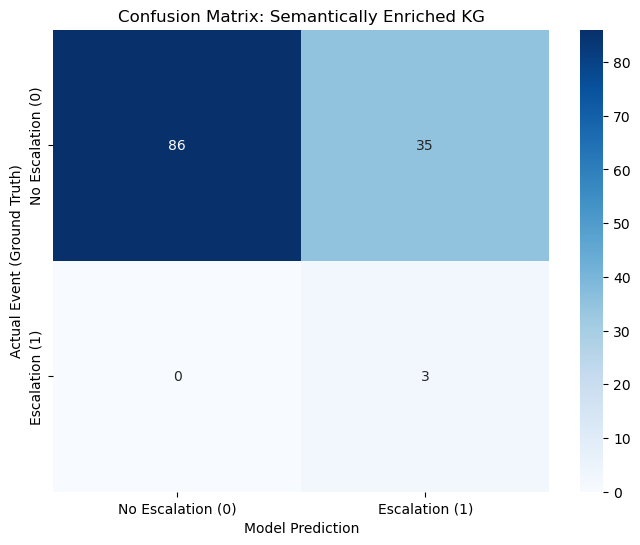

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
#import numpy as np
from sklearn.metrics import confusion_matrix

# 1. Convert raw probabilities into binary predictions using your optimized threshold
threshold = 0.30 
preds_binary_e_sna = (preds_e_sna >= threshold).astype(int)

# 2. Generate the confusion matrix using the Enriched Model's data
cm = confusion_matrix(y_true_e_sna, preds_binary_e_sna)

# 3. Plot the matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Escalation (0)', 'Escalation (1)'],
            yticklabels=['No Escalation (0)', 'Escalation (1)'])
plt.ylabel('Actual Event (Ground Truth)')
plt.xlabel('Model Prediction')
plt.title('Confusion Matrix: Semantically Enriched KG')

filename_conf_mtx = f"confusion_matrix_enriched_{timestamp}.png"
# Save and show
plt.savefig(filename_conf_mtx, dpi=300, bbox_inches='tight')
plt.show()

## Precision-Recall Curve

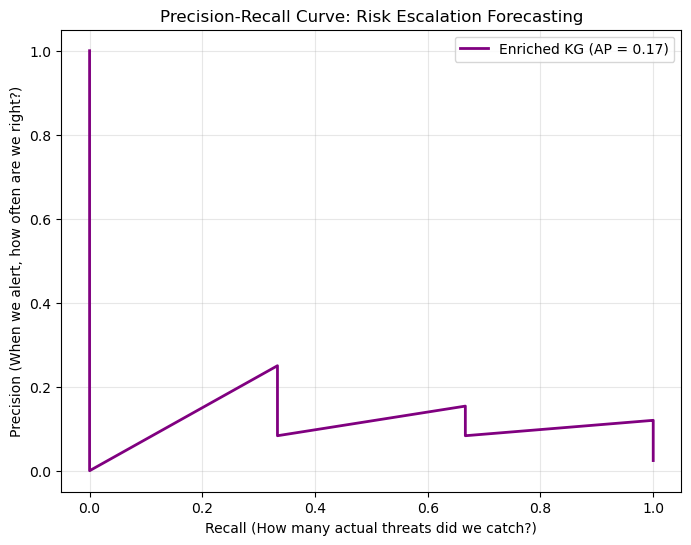

In [10]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# 1. Calculate Precision, Recall, and Average Precision (AP) scores
# Note: The PR curve inherently uses the raw probabilities (preds_e)
precision, recall, thresholds_pr = precision_recall_curve(y_true_e_sna, preds_e_sna)
ap_score = average_precision_score(y_true_e_sna, preds_e_sna)

# 2. Plot the curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='purple', lw=2, 
         label=f'Enriched KG (AP = {ap_score:.2f})')

plt.title('Precision-Recall Curve: Risk Escalation Forecasting')
plt.xlabel('Recall (How many actual threats did we catch?)')
plt.ylabel('Precision (When we alert, how often are we right?)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])

filename_curve_pr = f"precision_recall_curve_{timestamp}.png"
# Save and show
plt.savefig(filename_curve_pr, dpi=300, bbox_inches='tight')
plt.show()

## Final report

In [11]:
# Import your new function
from core.gnn_layer.risk_predict import generate_threat_report

print("==========================================================")
print("  GNN THREAT ESCALATION REPORT (ENRICHED KG)  ")
print("==========================================================\n")

# Generate alerts for any relationship with > 75% escalation probability
threat_alerts = generate_threat_report(trained_enriched_sna, enriched_data_sna, reverse_mapping_sna, threshold=0.75)

if not threat_alerts:
    print("✅ No high-risk escalations detected in the current network topology.")
else:
    for alert in threat_alerts:
        print(f"⚠️ HIGH RISK ({alert['probability']:.1f}%): {alert['source']} -> {alert['target']}")

  GNN THREAT ESCALATION REPORT (ENRICHED KG)  

⚠️ HIGH RISK (87.2%): O'Reilly -> Runner
⚠️ HIGH RISK (83.2%): Unknown_Assailant -> Torres
⚠️ HIGH RISK (79.2%): Attacker -> Batista
⚠️ HIGH RISK (79.0%): O'Reilly -> Younger Inmate
⚠️ HIGH RISK (78.9%): O'Reilly -> Assassination Target
⚠️ HIGH RISK (75.8%): O'Reilly -> Inmate
